# Creando un modelo de prediccion de partidos

Algo que se ha hecho muy popular durante el desarrollo del mundial fueron las estadisticas de "prediccion" sobre resultados de partidos, con estadisticas o con resultados mas deterministas, estos intentan predecir un partido utilizando los datos conocidos previos al partido.

Este notebook se enfocara justamente en uno de esos modelos, en el cual recogeremos los datos de la base de datos que nos parezcan utiles para determinar el resultado del partido, y los compararemos con el resultado del partido mediante un modelo de regresion multiple utilizando cuadrados minimos para luego verificar que tan acertadas son las predicciones que se pueden alcanzar con estos datos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import empiricaldist
import sqlite3
import scipy.stats
import statsmodels.api as sm
conn = sqlite3.connect("../data/Datos_Limpios.db")

In [58]:
plt.rcParams.update({
    "figure.facecolor": "#121314",
    "axes.facecolor": "#121314",
    "axes.edgecolor": "#FFFFFF",
    "axes.labelcolor": "#FFFFFF",
    "text.color": "#FFFFFF",
    "xtick.color": "#FFFFFF",
    "ytick.color": "#FFFFFF",
    "grid.color": "#2B2B2B",
    "lines.color": "#FFFFFF"
})

## ¿Que datos nos pueden ayudar a predecir un partido?

Para demostrar que datos vamos a usar para predecir, elijamos un partido ya terminado, y veamos que datos podemos obtener de ese partido dentro de la base de datos. Elijamos un partido reciente de world_cup_matches:

In [59]:
query = "SELECT * " \
"FROM world_cup_matches"
wcm = pd.read_sql_query(query, conn)
wcm.tail()

,match_id,date,home_team,home_team_id,away_team,away_team_id,round,home_score,away_score,neutral,...,away_xg,home_possession,away_possession,home_sot,away_sot,home_shots,away_shots,result,away_is_local,home_is_local
1063,48061,2026-07-11,Norway,127,England,53,Quarter-finals,1,2,1,...,0.96,48.0,52.0,4.0,8.0,13.0,14.0,away team win,0,0
1064,48062,2026-07-14,France,61,Spain,155,Semi-finals,0,2,1,...,1.63,49.0,51.0,3.0,2.0,10.0,10.0,away team win,0,0
1065,48063,2026-07-15,England,53,Argentina,7,Semi-finals,1,2,1,...,1.80,36.0,64.0,2.0,5.0,5.0,15.0,away team win,0,0
1066,48064,2026-07-18,France,61,England,53,Third-place match,4,6,1,...,2.88,46.0,54.0,9.0,11.0,19.0,19.0,away team win,0,0
1067,48065,2026-07-19,Spain,155,Argentina,7,Final,1,0,1,...,0.88,65.0,35.0,12.0,0.0,20.0,2.0,home team win,0,0


Quedemonos con Spain - Argentina (España - Argentina) en la final. Obtengamos el partido y sus datos:

In [60]:
partido = wcm[wcm["match_id"] == 48065]
partido

,match_id,date,home_team,home_team_id,away_team,away_team_id,round,home_score,away_score,neutral,...,away_xg,home_possession,away_possession,home_sot,away_sot,home_shots,away_shots,result,away_is_local,home_is_local
1067,48065,2026-07-19,Spain,155,Argentina,7,Final,1,0,1,...,0.88,65.0,35.0,12.0,0.0,20.0,2.0,home team win,0,0


El resultado del partido termino 1-0 para home_team, es decir España, que se puede ver en el valor de results (away team win).  
   No hubo tanda de penales, y el partido fue en cancha neutral (eso es lo que nos dice la columna neutral, 1 implica que el partido fue jugado en cancha neutral, y 0 que uno de los equipos fue local).

Obtengamos la fecha del partido y el identificador id de cada uno de los equipos:
(para esto pasemos la column date de wcm a formato DateTime)

In [61]:
wcm["date"] = pd.to_datetime(wcm["date"])
fecha = partido["date"].iloc[0]
fecha = pd.Timestamp(fecha)
fecha

Timestamp('2026-07-19 00:00:00')

In [62]:
home_team_id = partido["home_team_id"].iloc[0]
away_team_id = partido["away_team_id"].iloc[0]
home_team_id, away_team_id

(np.int64(155), np.int64(7))

España esta asociado al id 155 y Argentina al id 7.


Ahora nos vamos a enfocar en buscar todos los datos que nos puedan dar informacion para predecir el resultado de este partido.
Una tabla que ya vimos que teniamos en la base de datos es eloratings_clean, la cual guarda todos los cambios historicos en el puntaje ELO de la FIFA sobre cada equipo.  
 Esto nos va a permitir saber para cada partido, cual fue en ese momento el puntaje ELO en el cual la FIFA calificaba a ambos partidos antes de enfrentarse.

In [63]:
query = "SELECT * " \
"FROM eloratings_clean"
elo_ratings = pd.read_sql_query(query, conn)
elo_ratings

,date,team,rating,change,team_id
0,1872-11-30,England,2003,3,53.0
1,1872-11-30,Scotland,1997,-3,185.0
2,1873-03-08,England,2014,11,53.0
3,1873-03-08,Scotland,1986,-11,185.0
4,1874-03-07,England,2006,-8,53.0
...,...,...,...,...,...
6673,2025-12-13,Northern Mariana Islands,432,0,230.0
6674,2025-12-13,Cocos Islands,422,0,231.0
6675,2025-12-13,Palau,402,0,232.0
6676,2025-12-13,Eastern Samoa,389,0,214.0


Como vimos, cada fila representa un cambio al puntaje ELO FIFA de ese equipo, con su fecha. Rating nos dice el nuevo puntaje FIFA de ese equipo, change el cambio respecto a su ultimo puntaje registrado, y team_id nos ayuda a identificar por id el equipo.

A continuacion, filtramos elo_ratings a aquellos previos al dia del partido (elo_ratings_valido), para luego obtener de ese subquery valido los elos de cada equipo, y nos quedamos con el ultimo (mas reciente).

In [64]:
elo_ratings["date"] = pd.to_datetime(elo_ratings["date"]) # Aca pasamos
#date de elo ratings a formato Datetime como hicimos con wcm.
  
elo_ratings_valido = elo_ratings[elo_ratings["date"] < fecha]

elo_ratings_home = elo_ratings_valido[elo_ratings_valido["team_id"] == home_team_id]
home_team_rating = elo_ratings_home.tail(1)["rating"].iloc[0]

elo_ratings_away = elo_ratings_valido[elo_ratings_valido["team_id"] == away_team_id]
away_team_rating = elo_ratings_away.tail(1)["rating"].iloc[0]

home_team_rating, away_team_rating


(2171, 2113)

El elo rating de España antes del momento del partido era 2171, mientras que el de Argentina eraa 2113.   
Para obtener mas informacion del "momentum" de cada seleccion, obtengamos datos del rendimineto de estos equipos antes de mundial con results_shootouts, que tiene datos de todos los partidos a nivel selecciones.  
Pasamos la columna date de results_shootouts(rs) a formato DateTime de Pandas

In [65]:
query = "SELECT *" \
"FROM results_shootouts"

rs = pd.read_sql_query(query, conn)

rs["date"] = pd.to_datetime(rs["date"])
rs

,match_id,date,home_team,away_team,home_team_id,away_team_id,home_score,away_score,neutral,country,...,has_shootouts,winner_on_shootouts,winner,tournament,tournament_id,result,local_team_id,local,away_is_local,home_is_local
0,3204,1950-01-24,Zambia,DR Congo,183,194,1,0,0,Northern Rhodesia,...,0,NaN,Zambia,Friendly,97,home team win,183.0,home team,0,1
1,3205,1950-02-17,Egypt,Greece,51,67,2,0,0,Egypt,...,0,NaN,Egypt,Friendly,97,home team win,51.0,home team,0,1
2,3206,1950-02-26,Bolivia,Chile,22,36,2,0,0,Bolivia,...,0,NaN,Bolivia,Friendly,97,home team win,22.0,home team,0,1
3,3207,1950-02-26,Croatia,Serbia,42,144,4,1,0,Yugoslavia,...,0,NaN,Croatia,Friendly,97,home team win,144.0,away team,1,0
4,3208,1950-03-05,Italy,Belgium,84,17,3,1,0,Italy,...,0,NaN,Italy,Friendly,97,home team win,84.0,home team,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44857,48061,2026-07-11,Norway,England,127,53,1,2,1,United States,...,0,NaN,England,FIFA World Cup,1,away team win,NaN,NaN,0,0
44858,48062,2026-07-14,France,Spain,61,155,0,2,1,United States,...,0,NaN,Spain,FIFA World Cup,1,away team win,NaN,NaN,0,0
44859,48063,2026-07-15,England,Argentina,53,7,1,2,1,United States,...,0,NaN,Argentina,FIFA World Cup,1,away team win,NaN,NaN,0,0
44860,48064,2026-07-18,France,England,61,53,4,6,1,United States,...,0,NaN,England,FIFA World Cup,1,away team win,NaN,NaN,0,0


Luego aplicamos la misma logica para filtrar a solo resultados validos y no "ver el futuro", filtrando para ambas tablas que nos dicen datos de solo aquellos partidos que se dieron antes del dia del partido:

In [66]:
rs_valido = rs[rs["date"] < fecha]
rs_valido.tail()


,match_id,date,home_team,away_team,home_team_id,away_team_id,home_score,away_score,neutral,country,...,has_shootouts,winner_on_shootouts,winner,tournament,tournament_id,result,local_team_id,local,away_is_local,home_is_local
44856,48060,2026-07-11,Argentina,Switzerland,7,160,3,1,1,United States,...,0,NaN,Argentina,FIFA World Cup,1,home team win,NaN,NaN,0,0
44857,48061,2026-07-11,Norway,England,127,53,1,2,1,United States,...,0,NaN,England,FIFA World Cup,1,away team win,NaN,NaN,0,0
44858,48062,2026-07-14,France,Spain,61,155,0,2,1,United States,...,0,NaN,Spain,FIFA World Cup,1,away team win,NaN,NaN,0,0
44859,48063,2026-07-15,England,Argentina,53,7,1,2,1,United States,...,0,NaN,Argentina,FIFA World Cup,1,away team win,NaN,NaN,0,0
44860,48064,2026-07-18,France,England,61,53,4,6,1,United States,...,0,NaN,England,FIFA World Cup,1,away team win,NaN,NaN,0,0


Y hacemos lo mismo con wcm:

In [67]:
wcm_valido = wcm[wcm["date"] < fecha]
wcm_valido.tail()

,match_id,date,home_team,home_team_id,away_team,away_team_id,round,home_score,away_score,neutral,...,away_xg,home_possession,away_possession,home_sot,away_sot,home_shots,away_shots,result,away_is_local,home_is_local
1062,48060,2026-07-11,Argentina,7,Switzerland,160,Quarter-finals,3,1,1,...,0.53,59.0,41.0,7.0,5.0,22.0,11.0,home team win,0,0
1063,48061,2026-07-11,Norway,127,England,53,Quarter-finals,1,2,1,...,0.96,48.0,52.0,4.0,8.0,13.0,14.0,away team win,0,0
1064,48062,2026-07-14,France,61,Spain,155,Semi-finals,0,2,1,...,1.63,49.0,51.0,3.0,2.0,10.0,10.0,away team win,0,0
1065,48063,2026-07-15,England,53,Argentina,7,Semi-finals,1,2,1,...,1.80,36.0,64.0,2.0,5.0,5.0,15.0,away team win,0,0
1066,48064,2026-07-18,France,61,England,53,Third-place match,4,6,1,...,2.88,46.0,54.0,9.0,11.0,19.0,19.0,away team win,0,0


Ahora como dijimos, obtengamos para cada equipo los partidos que jugo ese equipo en el mundial antes del partido, si es que jugo alguno.  
En este caso si se dio que jugaron partidos, por que estamos prediciendo la final:

La logica de este codigo implica que guarde los partidos de wcm_valido en los cuales el equipo del cual nos interesa obtener datos este presente, ya sea como home_team o away_team.  
Ademas, deben ser partidos de la misma edicion mundialista, es decir, mismo año (wcm_valido ya se encarga de que no obtengamos datos futuros).

In [68]:
home_team_matches_wcm = wcm_valido[
    (wcm_valido["date"].dt.year == fecha.year) &
    (
        (wcm_valido["home_team_id"] == home_team_id) |
        (wcm_valido["away_team_id"] == home_team_id)
    )
]
home_team_matches_wcm

,match_id,date,home_team,home_team_id,away_team,away_team_id,round,home_score,away_score,neutral,...,away_xg,home_possession,away_possession,home_sot,away_sot,home_shots,away_shots,result,away_is_local,home_is_local
977,47975,2026-06-15,Spain,155,Cape Verde,33,Group stage,0,0,1,...,0.35,74.0,26.0,7.0,1.0,27.0,6.0,draw,0,0
1003,48001,2026-06-21,Spain,155,Saudi Arabia,142,Group stage,4,0,1,...,0.25,67.0,33.0,8.0,1.0,22.0,3.0,home team win,0,0
1029,48027,2026-06-26,Uruguay,176,Spain,155,Group stage,0,1,1,...,1.35,33.0,67.0,1.0,1.0,5.0,6.0,away team win,0,0
1047,48045,2026-07-02,Spain,155,Austria,10,Round of 32,3,0,1,...,0.32,65.0,36.0,10.0,0.0,23.0,5.0,home team win,0,0
1057,48055,2026-07-06,Portugal,137,Spain,155,Round of 16,0,1,1,...,1.42,45.0,56.0,2.0,6.0,10.0,15.0,away team win,0,0
1061,48059,2026-07-10,Spain,155,Belgium,17,Quarter-finals,2,1,1,...,1.15,68.0,32.0,8.0,2.0,17.0,5.0,home team win,0,0
1064,48062,2026-07-14,France,61,Spain,155,Semi-finals,0,2,1,...,1.63,49.0,51.0,3.0,2.0,10.0,10.0,away team win,0,0


Aplicamos la misma logica al otro equipo:

In [69]:
away_team_matches_wcm = wcm_valido[
    (wcm_valido["date"].dt.year == fecha.year) &
    (
        (wcm_valido["home_team_id"] == away_team_id) |
        (wcm_valido["away_team_id"] == away_team_id)
    )
]
away_team_matches_wcm

,match_id,date,home_team,home_team_id,away_team,away_team_id,round,home_score,away_score,neutral,...,away_xg,home_possession,away_possession,home_sot,away_sot,home_shots,away_shots,result,away_is_local,home_is_local
980,47978,2026-06-16,Argentina,7,Algeria,3,Group stage,3,0,1,...,0.42,48.0,52.0,6.0,0.0,10.0,7.0,home team win,0,0
1005,48003,2026-06-22,Argentina,7,Austria,10,Group stage,2,0,1,...,0.55,54.0,46.0,5.0,1.0,12.0,6.0,home team win,0,0
1031,48029,2026-06-27,Jordan,88,Argentina,7,Group stage,1,3,1,...,2.13,27.0,73.0,1.0,4.0,5.0,12.0,away team win,0,0
1049,48047,2026-07-03,Argentina,7,Cape Verde,33,Round of 32,3,2,1,...,0.46,64.0,37.0,10.0,5.0,22.0,16.0,home team win,0,0
1058,48056,2026-07-07,Argentina,7,Egypt,51,Round of 16,3,2,1,...,1.10,64.0,36.0,7.0,2.0,19.0,5.0,home team win,0,0
1062,48060,2026-07-11,Argentina,7,Switzerland,160,Quarter-finals,3,1,1,...,0.53,59.0,41.0,7.0,5.0,22.0,11.0,home team win,0,0
1065,48063,2026-07-15,England,53,Argentina,7,Semi-finals,1,2,1,...,1.80,36.0,64.0,2.0,5.0,5.0,15.0,away team win,0,0


### Generalizando...

Con esto ya podemos construir variables para identificar como vienen rindiendo ambos equipos en el mundial previo a su enfrentamiento.  
Esto lo tenemos que hacer cuidadosamente por que, como ya sabemos, 
en cada partido hay un home_team y un away_team, por lo cual para obtener adecuadamente las estadisticas de nuestro equipo y no mezclar datos, debemos primero revisar para cada partido si nuestro equipo es home_team o away_team para identificar como sacaremos los datos.

La siguiente funcion tienen como parametro un subquery de wcm y un team_id.  
 Utiliza una copia de wcm_sub, en la que para cada fila (partido) crea columnas que guardan los datos del partido adecuadamente a si el equipo esta representado como home_team o away_team.  
 Los datos que vamos a utilizar son:
 goles_anotados, goles_recibidos, xg, sot, shots, posesion, y cantidad de victorias y derrotas.

Finalmente devuelve la suma de todas estas estadisticas promediadas (utilizamos el promedio para generalizar este procedimientos a todas las fases).

In [70]:
def construir_variables_wcm(wcm_sub, team_id):

    wcm_sub = wcm_sub.copy()

    wcm_sub["posicion"] = np.where(
        wcm_sub["home_team_id"] == team_id,
        "home_team",
        "away_team"
    )

    wcm_sub["goles_anotados"] = np.where(
        wcm_sub["posicion"] == "home_team",
        wcm_sub["home_score"],
        wcm_sub["away_score"]
    )

    wcm_sub["goles_recibidos"] = np.where(
        wcm_sub["posicion"] == "home_team",
        wcm_sub["away_score"],
        wcm_sub["home_score"]
    )

    wcm_sub["xg"] = np.where(
        wcm_sub["posicion"] == "home_team",
        wcm_sub["home_xg"],
        wcm_sub["away_xg"]
    )

    wcm_sub["sot"] = np.where(
        wcm_sub["posicion"] == "home_team",
        wcm_sub["home_sot"],
        wcm_sub["away_sot"]
    )

    wcm_sub["posesion"] = np.where(
        wcm_sub["posicion"] == "home_team",
        wcm_sub["home_possession"],
        wcm_sub["away_possession"]
    )

    wcm_sub["shots"] = np.where(
        wcm_sub["posicion"] == "home_team",
        wcm_sub["home_shots"],
        wcm_sub["away_shots"]
    )

    wcm_sub["victoria"] = (
        wcm_sub["goles_anotados"] > wcm_sub["goles_recibidos"]
    ).astype(int)

    wcm_sub["derrota"] = (
        wcm_sub["goles_anotados"] < wcm_sub["goles_recibidos"]
    ).astype(int)

    avg_goles_anotados = wcm_sub["goles_anotados"].mean()
    avg_goles_recibidos = wcm_sub["goles_recibidos"].mean()
    avg_xg = wcm_sub["xg"].mean()
    avg_sot = wcm_sub["sot"].mean()
    avg_posesion = wcm_sub["posesion"].mean()
    avg_shots = wcm_sub["shots"].mean()
    avg_victorias = wcm_sub["victoria"].mean()
    avg_derrotas = wcm_sub["derrota"].mean()

    return (
        avg_goles_anotados,
        avg_goles_recibidos,
        avg_victorias,
        avg_derrotas,
        avg_xg,
        avg_sot,
        avg_posesion,
        avg_shots,
    )

Apliquemos esto a nuestro ejemplo:

In [71]:
construir_variables_wcm(home_team_matches_wcm, home_team_id)

(np.float64(1.8571428571428572),
 np.float64(0.14285714285714285),
 np.float64(0.8571428571428571),
 np.float64(0.0),
 np.float64(2.0814285714285714),
 np.float64(6.0),
 np.float64(64.0),
 np.float64(17.142857142857142))

In [72]:
construir_variables_wcm(away_team_matches_wcm, away_team_id)

(np.float64(2.7142857142857144),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(0.0),
 np.float64(2.0957142857142856),
 np.float64(6.285714285714286),
 np.float64(60.857142857142854),
 np.float64(16.0))

Podemos repetir este proceso para sacar mas datos de esta manera con results_shootouts. 
La ventaja de results_shootouts en este caso es que nos va a permitir sacar datos de una cantidad mayor de partidos antes de la prediccion. Por ejemplo, podemos crear una funcion similar que promedie sus estadisticas con los ultimos 10 partidos de la seleccion que jugo el partido.  

Esto tambien sera particularmente util en partidos tempranos del torneo, por que en dichas instancias wcm no nos va a poder decir mucho sobre su rendimiento. En cambio results_shootouts es un dataframe historico que contiene los ultimos partidos internacionales de cada seleccion, por lo cual nos va a aportar mayor informacion.

In [73]:
def construir_variables_rs(rs_sub, team_id):

    rs_sub = rs_sub.copy()

    rs_sub["posicion"] = np.where(
        rs_sub["home_team_id"] == team_id,
        "home_team",
        "away_team"
    )

    rs_sub["goles_anotados"] = np.where(
        rs_sub["posicion"] == "home_team",
        rs_sub["home_score"],
        rs_sub["away_score"]
    )

    rs_sub["goles_recibidos"] = np.where(
        rs_sub["posicion"] == "home_team",
        rs_sub["away_score"],
        rs_sub["home_score"]
    )


    rs_sub["victoria"] = (
        rs_sub["goles_anotados"] > rs_sub["goles_recibidos"]
    ).astype(int)

    rs_sub["derrota"] = (
        rs_sub["goles_anotados"] < rs_sub["goles_recibidos"]
    ).astype(int)

    avg_goles_anotados = rs_sub["goles_anotados"].mean()
    avg_goles_recibidos = rs_sub["goles_recibidos"].mean()
    avg_victorias = rs_sub["victoria"].mean()
    avg_derrotas = rs_sub["derrota"].mean()

    return (
        avg_goles_anotados,
        avg_goles_recibidos,
        avg_victorias,
        avg_derrotas
    )

Tambien apliquemos esta funcion al partido con el subconjunto correspondiente de results_shootouts.
Para esta tabla, como tiene registros historicos de partidos internacionales y no solamente partidos mundialistas, filtraremos por:  

-Ultimos 10 partidos de ese equipo antes del partido de la prediccion.  
-Partidos que no sean de mundiales, por que estos ya estarian en wcm y seria repetir informacion por ende sobremuestrear, en results_shootouts, tournament_id = 1 indica que ese partido fue disputado en mundial.  

In [74]:
away_team_matches_rs = rs[
    (rs["date"] < fecha) &
    (rs["tournament_id"] != 1) &
    (
        (rs["home_team_id"] == away_team_id) |
        (rs["away_team_id"] == away_team_id)
    )
].tail(10)

away_team_matches_rs

,match_id,date,home_team,away_team,home_team_id,away_team_id,home_score,away_score,neutral,country,...,has_shootouts,winner_on_shootouts,winner,tournament,tournament_id,result,local_team_id,local,away_is_local,home_is_local
43796,47000,2025-06-10,Argentina,Colombia,7,38,1,1,0,Argentina,...,0,NaN,NaN,FIFA World Cup qualification,2,draw,7.0,home team,0,1
43893,47097,2025-09-04,Argentina,Venezuela,7,179,3,0,0,Argentina,...,0,NaN,Argentina,FIFA World Cup qualification,2,home team win,7.0,home team,0,1
44004,47208,2025-09-09,Ecuador,Argentina,50,7,1,0,0,Ecuador,...,0,NaN,Ecuador,FIFA World Cup qualification,2,home team win,50.0,home team,0,1
44092,47296,2025-10-10,Argentina,Venezuela,7,179,1,0,1,United States,...,0,NaN,Argentina,Friendly,97,home team win,NaN,NaN,0,0
44175,47379,2025-10-14,Puerto Rico,Argentina,188,7,0,6,1,United States,...,0,NaN,Argentina,Friendly,97,away team win,NaN,NaN,0,0
44254,47458,2025-11-14,Angola,Argentina,5,7,0,2,0,Angola,...,0,NaN,Argentina,Friendly,97,away team win,5.0,home team,0,1
44504,47708,2026-03-27,Argentina,Mauritania,7,108,2,1,0,Argentina,...,0,NaN,Argentina,Friendly,97,home team win,7.0,home team,0,1
44573,47777,2026-03-31,Argentina,Zambia,7,183,5,0,0,Argentina,...,0,NaN,Argentina,Friendly,97,home team win,7.0,home team,0,1
44694,47898,2026-06-06,Argentina,Honduras,7,74,2,0,1,United States,...,0,NaN,Argentina,Friendly,97,home team win,NaN,NaN,0,0
44733,47937,2026-06-09,Argentina,Iceland,7,77,3,0,1,United States,...,0,NaN,Argentina,Friendly,97,home team win,NaN,NaN,0,0


In [75]:
home_team_matches_rs = rs[
    (rs["date"] < fecha) &
    (rs["tournament_id"] != 1) &
    (
        (rs["home_team_id"] == home_team_id) |
        (rs["away_team_id"] == home_team_id)
    )
].tail(10)

home_team_matches_rs

,match_id,date,home_team,away_team,home_team_id,away_team_id,home_score,away_score,neutral,country,...,has_shootouts,winner_on_shootouts,winner,tournament,tournament_id,result,local_team_id,local,away_is_local,home_is_local
43897,47101,2025-09-04,Bulgaria,Spain,27,155,0,3,0,Bulgaria,...,0,NaN,Spain,FIFA World Cup qualification,2,away team win,27.0,home team,0,1
43976,47180,2025-09-07,Turkey,Spain,170,155,0,6,0,Turkey,...,0,NaN,Spain,FIFA World Cup qualification,2,away team win,170.0,home team,0,1
44130,47334,2025-10-11,Spain,Georgia,155,64,2,0,0,Spain,...,0,NaN,Spain,FIFA World Cup qualification,2,home team win,155.0,home team,0,1
44186,47390,2025-10-14,Spain,Bulgaria,155,27,4,0,0,Spain,...,0,NaN,Spain,FIFA World Cup qualification,2,home team win,155.0,home team,0,1
44284,47488,2025-11-15,Georgia,Spain,64,155,0,4,0,Georgia,...,0,NaN,Spain,FIFA World Cup qualification,2,away team win,64.0,home team,0,1
44368,47572,2025-11-18,Spain,Turkey,155,170,2,2,0,Spain,...,0,NaN,NaN,FIFA World Cup qualification,2,draw,155.0,home team,0,1
44531,47735,2026-03-27,Spain,Serbia,155,144,3,0,0,Spain,...,0,NaN,Spain,Friendly,97,home team win,155.0,home team,0,1
44589,47793,2026-03-31,Spain,Egypt,155,51,0,0,0,Spain,...,0,NaN,NaN,Friendly,97,draw,155.0,home team,0,1
44669,47873,2026-06-04,Spain,Iraq,155,81,1,1,0,Spain,...,0,NaN,NaN,Friendly,97,draw,155.0,home team,0,1
44731,47935,2026-06-08,Peru,Spain,134,155,1,3,1,Mexico,...,0,NaN,Spain,Friendly,97,away team win,NaN,NaN,0,0


Con esto ya podemos para cada partido conseguir una construccion de variables que nos van a ayudar a entender el desempeño de ambos equipos antes del momento del partido.  

## Preparando los datos para entrenamiento
Como ya podemos para cada partido hacer una construccion de variables que nos pueden llegar a dar informacion de este, podemos crear un primer dataset de entrenamiento para modelos, en este para cada partido  meteremos los datos que construimos.  
Tomaremos como subconjunto valido los partidos tales que tengan los datos que vamos a usar.  
Como para el primer modelo vamos a utilizar datos del desarrollo de los partidos, filtraremos por partidos que no tengan valores NaN en estas columnas

In [76]:
columns = ["home_xg", "away_xg", "home_sot", "away_sot", "home_possession",
   "away_possession", "home_shots", "away_shots"]
subconjunto_valido = wcm.dropna(subset=columns)

subconjunto_valido["date"].min(), subconjunto_valido["date"].max(), subconjunto_valido["date"].count()

(Timestamp('2026-06-11 00:00:00'),
 Timestamp('2026-07-19 00:00:00'),
 np.int64(104))

El subconjunto que utilizaremos en este ejemplo tendra pocos partidos , 104.
Esto por que como ya vimos en otro notebook, la mayoria de estas estadisticas solo las pudimos conseguir en el dataset para el mundial 2026.  
Esto implica que, si no usamos algunos de estos datos, aun que perdamos informacion reciente, la cantidad de partidos que perteneceran al conjunto de entrenamiento sera mucho mayor, lo cual puede compensar la falta de datos. Por el momento quedemonos con este conjunto de datos con pocos partidos.

Tambien, para evitar llenar el dataset de entrenamiento, en vez de poner por cada estadistica "home_estadistica" y "away_estadistica", pondremos simplemente "estadistica_diff". Es decir la diferencia del equipo home con respecto al equipo away en esa estadistica. Esto probablemente ayude mas al modelo a hacer predicciones.

In [77]:
dataset_entrenamiento = pd.DataFrame(
    columns=("match_id", "date", "home_team", "away_team", "home_team_id", "away_team_id", "elo_diff", "goles_anotados_diff_wcm", "goles_recibidos_diff_wcm",
              "victorias_diff_wcm", "derrotas_diff_wcm", "xg_diff", "sot_diff", "possession_diff", "shots_diff", "home_local", "away_local",
             "goles_anotados_diff_rs", "goles_recibidos_diff_rs", "victorias_diff_rs", "derrotas_diff_rs",
             "result")
)

Ahora si, por cada partido del conjunto del entrenamiento, llenaremos sus datos respectivamente al dataset de entrenamiento con el siguiente codigo (la funcion conseguir_elo resume el procedimiento de extraccion de valor elo de cada partido para ese momento). 

In [78]:
def conseguir_elo(home_team_id, away_team_id, fecha):
    elo_ratings_valido = elo_ratings[elo_ratings["date"] < fecha]

    elo_ratings_home = elo_ratings_valido[elo_ratings_valido["team_id"] == home_team_id]
    home_team_rating = elo_ratings_home.tail(1)["rating"].iloc[0]

    elo_ratings_away = elo_ratings_valido[elo_ratings_valido["team_id"] == away_team_id]
    away_team_rating = elo_ratings_away.tail(1)["rating"].iloc[0]

    return home_team_rating, away_team_rating


In [79]:
for _, partido in subconjunto_valido.iterrows():
    fecha = partido["date"]
    home_team_id = partido["home_team_id"]
    away_team_id = partido["away_team_id"]

    home_team_matches_wcm = wcm[
    (wcm["date"].dt.year == fecha.year) &
    (wcm["date"] < fecha) &
    (
        (wcm["home_team_id"] == home_team_id) |
        (wcm["away_team_id"] == home_team_id)
    )]
    
    away_team_matches_wcm = wcm[
    (wcm["date"].dt.year == fecha.year) &
    (wcm["date"] < fecha) &
    (
        (wcm["home_team_id"] == away_team_id) |
        (wcm["away_team_id"] == away_team_id)
    )]

    home_team_matches_rs = rs[
    (rs["date"] < fecha) &
    (rs["tournament_id"] != 1) &
    (
        (rs["home_team_id"] == home_team_id) |
        (rs["away_team_id"] == home_team_id)
    )].tail(10)

    away_team_matches_rs = rs[
    (rs["date"] < fecha) &
    (rs["tournament_id"] != 1) &
    (
        (rs["home_team_id"] == away_team_id) |
        (rs["away_team_id"] == away_team_id)
    )
    ].tail(10)
     
    stats_home_rs = construir_variables_rs(home_team_matches_rs, home_team_id)
    stats_away_rs = construir_variables_rs(away_team_matches_rs, away_team_id)

    stats_home_wcm = construir_variables_wcm(home_team_matches_wcm, home_team_id)
    stats_away_wcm = construir_variables_wcm(away_team_matches_wcm, away_team_id)

    home_elo, away_elo = conseguir_elo(home_team_id, away_team_id, fecha)

    dataset_entrenamiento.loc[len(dataset_entrenamiento)] = [
        partido["match_id"],
        fecha,
        partido["home_team"],
        partido["away_team"],
        home_team_id,
        away_team_id,
        home_elo - away_elo,

        stats_home_wcm[0] - stats_away_wcm[0], #goles anotados wcm diff
        stats_home_wcm[1] - stats_away_wcm[1], #goles recibidos wcm diff
        stats_home_wcm[2] - stats_away_wcm[2], #victorias wcm diff 
        stats_home_wcm[3] - stats_away_wcm[3], #derrotas wcm diff
        stats_home_wcm[4] - stats_away_wcm[4], #xg diff
        stats_home_wcm[5] - stats_away_wcm[5], #sot diff
        stats_home_wcm[6] - stats_away_wcm[6], # posesion diff
        stats_home_wcm[7] - stats_away_wcm[7], #shots diff
        
        partido["home_is_local"],
        partido["away_is_local"],

        stats_home_rs[0] - stats_away_rs[0], # goles anotados rs diff
        stats_home_rs[1] - stats_away_rs[1], # goles recibidos rs diff
        stats_home_rs[2] - stats_away_rs[2], # victorias rs diff
        stats_home_rs[3] - stats_away_rs[3], # derrotas rs diff
        partido["result"]

        ]

Con esto tenemos un dataset preparado para entrenar un modelo. Con el cual podemos utilizar el metodo training series - test series para entrenar y verificar la eficacia de este modelo para predecir los partidos futuros del mundial.

In [80]:
dataset_entrenamiento

,match_id,date,home_team,away_team,home_team_id,away_team_id,elo_diff,goles_anotados_diff_wcm,goles_recibidos_diff_wcm,victorias_diff_wcm,...,sot_diff,possession_diff,shots_diff,home_local,away_local,goles_anotados_diff_rs,goles_recibidos_diff_rs,victorias_diff_rs,derrotas_diff_rs,result
0,47962,2026-06-11,South Korea,Czech Republic,153,45,53,NaN,NaN,NaN,...,NaN,NaN,NaN,0,0,-0.7,0.3,0.1,0.2,home team win
1,47963,2026-06-11,Mexico,South Africa,110,152,304,NaN,NaN,NaN,...,NaN,NaN,NaN,1,0,0.1,-0.6,0.1,-0.2,home team win
2,47964,2026-06-12,Canada,Bosnia and Herzegovina,32,23,231,NaN,NaN,NaN,...,NaN,NaN,NaN,1,0,-0.9,-0.6,0.1,0.0,draw
3,47965,2026-06-12,United States,Paraguay,175,133,-86,NaN,NaN,NaN,...,NaN,NaN,NaN,1,0,0.6,0.7,0.1,0.0,home team win
4,47966,2026-06-13,Australia,Turkey,9,170,-106,NaN,NaN,NaN,...,NaN,NaN,NaN,0,0,-1.2,-0.3,-0.3,0.3,home team win
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,48061,2026-07-11,Norway,England,127,53,-120,0.200000,0.800000,0.000000,...,-1.400000,-5.200000,-5.400000,0,0,0.7,0.6,-0.2,0.0,away team win
100,48062,2026-07-14,France,Spain,61,155,-109,0.833333,0.166667,0.166667,...,1.166667,-7.500000,0.000000,0,0,-0.3,0.5,0.1,0.1,away team win
101,48063,2026-07-15,England,Argentina,53,7,-71,-0.666667,0.000000,-0.166667,...,0.166667,-3.166667,-0.500000,0,0,-0.1,-0.1,0.0,0.0,away team win
102,48064,2026-07-18,France,England,61,53,20,0.285714,-0.571429,0.142857,...,1.142857,3.142857,3.000000,0,0,0.1,0.7,0.0,0.0,away team win


El dataset de entrenamiento tiene algunos valores NaN en algunos partidos de wcm.  

Esto ocurre naturalmente porque como wcm saca datos de los partidos previos del mundial al partido a evaluar, en el primer partido no tiene datos previos para registrar, por lo cual los valores de wcm para esos datos serian NaN.  

Por esto mismo, solo seleccionaremos por el momento partidos que no tengan valores NaN del dataset: 

In [81]:
dataset_entrenamiento = dataset_entrenamiento.dropna()
dataset_entrenamiento

,match_id,date,home_team,away_team,home_team_id,away_team_id,elo_diff,goles_anotados_diff_wcm,goles_recibidos_diff_wcm,victorias_diff_wcm,...,sot_diff,possession_diff,shots_diff,home_local,away_local,goles_anotados_diff_rs,goles_recibidos_diff_rs,victorias_diff_rs,derrotas_diff_rs,result
24,47986,2026-06-18,Switzerland,Bosnia and Herzegovina,160,23,326,0.000000,0.000000,0.000000,...,4.000000,29.000000,18.000000,0,0,0.2,-0.2,0.2,0.0,home team win
25,47987,2026-06-18,Canada,Qatar,32,138,375,0.000000,0.000000,0.000000,...,0.000000,29.000000,6.000000,1,0,0.4,-1.1,0.3,-0.4,home team win
26,47988,2026-06-18,Czech Republic,South Africa,45,152,200,1.000000,0.000000,0.000000,...,2.000000,-2.000000,4.000000,0,0,0.7,-0.1,0.0,-0.2,draw
27,47989,2026-06-18,Mexico,South Korea,110,153,51,0.000000,-1.000000,0.000000,...,-2.000000,-1.000000,1.000000,1,0,0.1,-0.8,0.0,-0.2,home team win
28,47990,2026-06-19,United States,Australia,175,9,-27,2.000000,1.000000,0.000000,...,2.000000,37.000000,7.000000,1,0,0.5,0.7,0.0,0.0,home team win
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,48061,2026-07-11,Norway,England,127,53,-120,0.200000,0.800000,0.000000,...,-1.400000,-5.200000,-5.400000,0,0,0.7,0.6,-0.2,0.0,away team win
100,48062,2026-07-14,France,Spain,61,155,-109,0.833333,0.166667,0.166667,...,1.166667,-7.500000,0.000000,0,0,-0.3,0.5,0.1,0.1,away team win
101,48063,2026-07-15,England,Argentina,53,7,-71,-0.666667,0.000000,-0.166667,...,0.166667,-3.166667,-0.500000,0,0,-0.1,-0.1,0.0,0.0,away team win
102,48064,2026-07-18,France,England,61,53,20,0.285714,-0.571429,0.142857,...,1.142857,3.142857,3.000000,0,0,0.1,0.7,0.0,0.0,away team win


Por culpa de esto, perdimos 24 partidos de entrenamiento, lo cual nos deja con 80 partidos para evaluar sobre este mundial. ahora si obtengaamos la particion test_series - training series.  
Como tenemos los datos que necesitamos de 80 partidos, hagamos que la division trainig/test sea 60/20:  


In [82]:
training_series = dataset_entrenamiento.iloc[:60].copy()
test_series = dataset_entrenamiento.iloc[60:].copy()


## Creando modelos

Los datos con los que queremos entrenar el modelo para que nos diga el resultado de la variable result la cual nos puede dar como resultado categorico home team win, away team win o draw.  
Por lo cual no podemos usar una regresion multiple comun ni una regresion logistica binaria.  


In [83]:
training_series["result"].values.unique()

<StringArray>
['home team win', 'draw', 'away team win']
Length: 3, dtype: str


 Para esto necesitamos utilizar un modelo de regresion logistica multinomial, el cual permite predecir variables categoricas con mas de dos categorias no ordenadas con multiples variables predictoras. 

 Para crear un buen modelo, hagamos multiples modelos, y luego verifiquemos su capacidad predictiva fuera del training split.  

 Empecemos con el primer modelo utilizando solo localidad y elo:

In [84]:
X = training_series[["elo_diff", "home_local", "away_local"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M1 = sm.MNLogit(y, X)
resultado = M1.fit()

display(resultado.summary())

         Current function value: 0.685425
         Iterations: 35


LinAlgError: Singular matrix

El modelo se rompio, esto es debido a la alta relacion entre ambas variables home_local y away_local. El error nos da un aviso de esto al señalarnos el error "Singular matrix".   
Veamos si podemos solucionar esto solo usando una de estas variables, como en la mayoria de los datos el equipo que es local aparece correctamente como home_local, quedemonos con home_local:  

In [114]:
X = training_series[["elo_diff", "home_local"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M1 = sm.MNLogit(y, X)
resultado = M1.fit()

display(resultado.summary())

         Current function value: 0.685425
         Iterations: 35


c:\Users\Maxi\Desktop\Proyecto_Mundial\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:858: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mnfit = base.LikelihoodModel.fit(


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       54
Method:                           MLE   Df Model:                            4
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.3337
Time:                        18:47:39   Log-Likelihood:                -41.125
converged:                      False   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 2.462e-08
========================================================================================
         result=draw       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.2834      0.513     -0.552      0.581      -1.289       0.722
elo_diff                 0.0088      0.003      3.104      0.002       0.003       0.014
home_local             -21.6900   4.89e+04     -0.000      1.000   -9.59e+04    9.59e+04
----------------------------------------------------------------------------------------
result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.0706      0.508     -0.139      0.889      -1.066       0.925
elo_diff                 0.0114      0.003      3.933      0.000       0.006       0.017
home_local               1.3497      1.068      1.264      0.206      -0.743       3.443
========================================================================================
"""

El modelo no se rompio, pero nos dicen que "Maximum number of iterations has been exceeded", esto implica que el modelo no llego a efectuar en las 35 iteraciones que tiene como limite las ecuaciones del modelo que mas puedan ajustarse a estos datos. Por lo cual no puede usarse este modelo tal y como esta.  
El problema parece ser home_local tambien, nos da una pista su error estandar extremo en ambas categorias. Esto no implica que la localia tenga poca capacidad predictiva, sino que con esta muestra y este modelo no se puede estimar su efecto.  
Veamos la distribucion de los valores de home_local sobre los 3 posibles resultados del partido:


In [115]:
pd.crosstab(
    training_series["home_local"],
    training_series["result"],
    margins=True
)

result,away team win,draw,home team win,All
home_local,,,,
0,18,11,23,52
1,2,0,6,8
All,20,11,29,60


Esto nos deja mas claro el problema, no hay empates cuando el equipo es local, por lo cual el modelo intenta estimar un coeficiente inestable.  
Por este notebook, hagamos modelos ignorando la localidad, enfoquemonos en este primer modelo solo con elo entonces:  

In [116]:
X = training_series[["elo_diff"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M1 = sm.MNLogit(y, X)
resultado = M1.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.733595
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       56
Method:                           MLE   Df Model:                            2
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.2868
Time:                        18:47:40   Log-Likelihood:                -44.016
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 2.052e-08
========================================================================================
         result=draw       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.4098      0.501     -0.818      0.413      -1.391       0.572
elo_diff                 0.0092      0.003      3.196      0.001       0.004       0.015
----------------------------------------------------------------------------------------
result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.2505      0.437      0.573      0.566      -0.606       1.107
elo_diff                 0.0109      0.003      3.905      0.000       0.005       0.016
========================================================================================
"""

La categoria de referencia es away team win, lo que quiere decir que M1 esta comparando los coeficientes como:  
-draw vs away team win.  
-home team win vs away team win.  

El valor p del elo es significativo para ambas categorias. A su vez, su coeficiente es positivo en los dos casos, por lo cual una mayor diferencia de elo a favor del home team incrementa las probabilidades relativas de que haya empate o victoria a favor del home team frente a una victoria visitante.   

El pseudo R2 de m1 es 0.2868, este valor indica que este modelo con diferencias de elo muestra una mejora considerable respecto al modelo nulo. Agregemos variables para evaluar si mejoran el ajuste.  

Otro valor importante para el ajuste es Log-Likelihood, que es la suma del logaritmo de las probabilidades que predice el modelo correctamente sobre su resultado real en el training set. Por la propiedad de que el logaritmo de una propiedad es negativa, este valor es negativo. Nos interesa que este valor sea lo mayor posible, es decir que un modelo mejor ajustado que M1 deberia tener un log-Likelihood mayor a -44.016. 
 LL-Null nos permite interpretar mejor este ultimo valor, LL-Null es justamente el valor de Log-Likelihood que obtiene el modelo nulo bajo esta muestra. En este caso LL-Null es -61.71, por lo que nuestro modelo con solo elo mejora este valor por las probabilidades que le asigna el ajuste con el elo de -61.71 a -44.016.

Sigamos con un nuevo modelo que tenga tambien elo diff, pero tambien otras variables del ultimo rendimiento en el mismo mundial.

In [117]:
X = training_series[["elo_diff", "goles_anotados_diff_wcm",
     "goles_recibidos_diff_wcm", "victorias_diff_wcm", "derrotas_diff_wcm"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M2 = sm.MNLogit(y, X)
resultado = M2.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.679096
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       48
Method:                           MLE   Df Model:                           10
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.3398
Time:                        18:47:40   Log-Likelihood:                -40.746
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 7.674e-06
============================================================================================
             result=draw       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -0.2858      0.554     -0.516      0.606      -1.371       0.799
elo_diff                     0.0104      0.004      2.949      0.003       0.003       0.017
goles_anotados_diff_wcm     -0.4316      0.419     -1.031      0.302      -1.252       0.389
goles_recibidos_diff_wcm     0.0486      0.459      0.106      0.916      -0.851       0.948
victorias_diff_wcm          -0.8181      1.489     -0.549      0.583      -3.737       2.101
derrotas_diff_wcm           -2.6090      2.259     -1.155      0.248      -7.037       1.819
--------------------------------------------------------------------------------------------
    result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                        0.2015      0.510      0.395      0.693      -0.798       1.201
elo_diff                     0.0122      0.003      3.497      0.000       0.005       0.019
goles_anotados_diff_wcm     -0.4982      0.388     -1.283      0.199      -1.259       0.263
goles_recibidos_diff_wcm     0.1452      0.437      0.332      0.740      -0.712       1.002
victorias_diff_wcm          -0.8442      1.374     -0.614      0.539      -3.538       1.849
derrotas_diff_wcm           -4.0899      2.171     -1.883      0.060      -8.346       0.166
============================================================================================
"""

Vemos que en M2 elo mantiene su significancia estadistica con respecto a las demas variables, con un valor p bajo y coeficiente positivo. El valor Pseudo R2 aumento de 0.2868 a 0.3398 y el loglikelihood bajo de -44.016 a -40.746, por lo cual, por lo menos dentro de esta muestra, el modelo con estadisticas generales de wcm muestra un mejor ajuste que el modelo solo con el elo. 

De las variables wcm que introdujimos, la  mayoria no muestra gran evidencia estadistica, pero como vimos estas permitieron al modelo mejore su ajuste sobre la serie de entrenamiento.  
Por ejemplo, en home win derrotas_diff_wcm, tiene valor p 0.060 y coeficiente negativo, el ultimo tiene sentido por que nos dice que a mayor promedio de derrotas del visitante (signo negativo), mayor la probabilidad de que el local gane o empate.  
Pero esto hay que tomarlo con pinzas, ya que su error estandar tambien es bastante grande, 2.171, y ademas, la muestra es chica, de 60 partidos.  
La mayoria de las variables tienen valor p muy debil, que parecen no aportar mucha informacion. El peligro de estas variables es que el modelo puede intentar usarlas para ajustarse a los resultados del training set, pero haciendo esto puede perder generalidad sobre su capacidad predictiva en general.
Con una version mas parsimoniosa de este modelo podemos verificar si podemos mantener la mayoria del ajuste con menos variables y reducir el riesgo del sobreajuste.

Esto nos presenta la cuestion de si tomar estas variables o no. Para esta cuestion podemos dividir este modelo en dos versiones:  
-M2 como el modelo que recien hicimos, con todas las variables explicativas y una posible mejora en la prediccion utilizando variables con mayor correlacion con las demas brindando menos informacion.  
-M2a con pocas variables significativamente fuertes que nos parecen dar mucha informacion sobre el resultado del partido.  


In [118]:
X = training_series[["elo_diff", "goles_anotados_diff_wcm",
                           "derrotas_diff_wcm"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M2a = sm.MNLogit(y, X)
resultado = M2a.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.685223
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       52
Method:                           MLE   Df Model:                            6
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.3338
Time:                        18:47:40   Log-Likelihood:                -41.113
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 2.634e-07
===========================================================================================
            result=draw       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -0.3517      0.529     -0.665      0.506      -1.389       0.686
elo_diff                    0.0101      0.003      3.023      0.003       0.004       0.017
goles_anotados_diff_wcm    -0.4462      0.327     -1.363      0.173      -1.088       0.195
derrotas_diff_wcm          -1.9170      1.705     -1.124      0.261      -5.260       1.426
-------------------------------------------------------------------------------------------
   result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       0.1159      0.489      0.237      0.813      -0.843       1.075
elo_diff                    0.0118      0.003      3.579      0.000       0.005       0.018
goles_anotados_diff_wcm    -0.4805      0.306     -1.568      0.117      -1.081       0.120
derrotas_diff_wcm          -3.1444      1.612     -1.950      0.051      -6.304       0.015
===========================================================================================
"""

 M2a es la version mas parsimonica, con menos variables explicativas que muestran mas informacion, en este caso podemos ver una sutil peora en el pseudo R2 de m2 con m2a (0.3398 a 0.3338) y en el log likelihood (-40.74 a -41.11),  a coste de dos variables explicativas mas que, por mas que brinden informacion redundante, pueden ayudar en prediccion.  
 Ademas ahora el valor p de las variables y el error estandar es bastante menor que antes. Por lo que sin las otras variables que compartian informacion, estos resultados nos dan informacion considerablemente util dentro del training set.

Apliquemos esto tambien con los siguientes modelos.  

Comparemos el resultado de M2 con el de otro que utilice datos de rs, es decir partidos previos al mundial:

In [119]:
X = training_series[["elo_diff", "goles_anotados_diff_rs",
     "goles_recibidos_diff_rs", "victorias_diff_rs", "derrotas_diff_rs"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M3 = sm.MNLogit(y, X)
resultado = M3.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.610313
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       48
Method:                           MLE   Df Model:                           10
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.4067
Time:                        18:47:40   Log-Likelihood:                -36.619
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 2.455e-07
===========================================================================================
            result=draw       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -0.1285      0.682     -0.188      0.851      -1.464       1.207
elo_diff                    0.0089      0.004      2.098      0.036       0.001       0.017
goles_anotados_diff_rs     -0.6429      1.096     -0.587      0.558      -2.791       1.505
goles_recibidos_diff_rs    -2.7821      1.919     -1.450      0.147      -6.543       0.978
victorias_diff_rs          -1.4158      3.606     -0.393      0.695      -8.483       5.651
derrotas_diff_rs           -4.2295      5.023     -0.842      0.400     -14.074       5.615
-------------------------------------------------------------------------------------------
   result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       0.7722      0.586      1.317      0.188      -0.377       1.921
elo_diff                    0.0111      0.004      2.774      0.006       0.003       0.019
goles_anotados_diff_rs      0.4892      0.939      0.521      0.602      -1.352       2.330
goles_recibidos_diff_rs    -3.7127      1.754     -2.117      0.034      -7.150      -0.275
victorias_diff_rs          -1.9709      3.102     -0.635      0.525      -8.051       4.109
derrotas_diff_rs            2.5572      4.201      0.609      0.543      -5.677      10.792
===========================================================================================
"""

M3 parece ajustarse mejor a los datos de entrenamiento que M1, el Pseudo R2 pasa de 0.2868  a 0.4067 y el loglikelihood de -44.01 a -36.61 
Elo diff sigue siendo importante, lo cual nos muestra que nos da informacion que no tenemos en ninguno otro de los modelos, y su coeficiente sigue siendo positivo.  
Dentro de las variables rs, goles_recibidos_diff_rs, es estadisticamente significativa para predecir home team win (coef = -3.71, p = 0.034), no tanto para empate. El coeficiente negativo nos indica que, con menos goles recibidos del local respecto al visitante recientemente, se asocia una mayor probabilidad de victoria local frente a visitante. Luego habra que comparar su eficiencia fuera de esta muestra.  

Los errores estandar en esta muestra parecen bastante altos, esto puede explicar por que los coeficiente pueden ser enormes pero no tan estadisticamente significativos.  

Tomamos como version parsimonica la que solo utiliza elo + goles_recibidos_diff_rs.

In [120]:
X = training_series[["elo_diff", "goles_recibidos_diff_rs"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M3a = sm.MNLogit(y, X)
resultado = M3a.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.642160
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       54
Method:                           MLE   Df Model:                            4
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.3757
Time:                        18:47:40   Log-Likelihood:                -38.530
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 2.057e-09
===========================================================================================
            result=draw       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -0.0146      0.601     -0.024      0.981      -1.192       1.163
elo_diff                    0.0079      0.003      2.291      0.022       0.001       0.015
goles_recibidos_diff_rs    -3.5706      1.310     -2.726      0.006      -6.138      -1.003
-------------------------------------------------------------------------------------------
   result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       0.7517      0.537      1.400      0.162      -0.301       1.804
elo_diff                    0.0104      0.003      3.184      0.001       0.004       0.017
goles_recibidos_diff_rs    -2.6565      1.176     -2.258      0.024      -4.962      -0.351
===========================================================================================
"""

Esta version nos muestra que ambas variables son estadisticamente significativas, con valores p menores a 5%.   
El pseudo R2 cayo de 0.4067 a 0.3757 y el loglikelihood bajo de -36.61 a -38.53. Por lo cual en la muestra de entrenamiento, M3 parece ajustarse mejor con mas variables explicativas, por mas que gran parte de su aporte pueda ser redundante y no estadisticamente significativo. 


Comparando los modelos de M2 y M3 con respecto a M1, rs parece ajustar mas informacion para ajuste que wcm dentro de esta muestra.  



Hagamos a continuacion un modelo con estadisticas mas modernas: Xg, shots, sot y possession.

In [121]:

X = training_series[["elo_diff", "xg_diff", "sot_diff", "shots_diff",  "possession_diff"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M4 = sm.MNLogit(y, X)
resultado = M4.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.637743
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       48
Method:                           MLE   Df Model:                           10
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.3800
Time:                        18:47:40   Log-Likelihood:                -38.265
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 9.822e-07
========================================================================================
         result=draw       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.2097      0.627     -0.335      0.738      -1.438       1.019
elo_diff                 0.0135      0.004      3.036      0.002       0.005       0.022
xg_diff                  0.3513      0.728      0.483      0.629      -1.076       1.778
sot_diff                -0.8860      0.414     -2.141      0.032      -1.697      -0.075
shots_diff               0.4055      0.181      2.235      0.025       0.050       0.761
possession_diff         -0.0729      0.056     -1.290      0.197      -0.184       0.038
----------------------------------------------------------------------------------------
result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.5740      0.553      1.038      0.299      -0.510       1.658
elo_diff                 0.0145      0.004      3.445      0.001       0.006       0.023
xg_diff                  0.5132      0.648      0.792      0.428      -0.756       1.783
sot_diff                -0.8540      0.392     -2.179      0.029      -1.622      -0.086
shots_diff               0.2471      0.160      1.543      0.123      -0.067       0.561
possession_diff         -0.0130      0.050     -0.261      0.794      -0.110       0.085
========================================================================================
"""

El pseudo R2 es 0.38, y el Log-Likelihood es -38.26, las estadisticas modernas del partido parecen tambien dar informacion util para ajuste.  
Elo diff y sot diff parecen aportar informacion nueva cada una con respecto a las demas variables, con un valor p considerablemente bajo.  
shots diff parece solo ser estadisticamente significativa en empate, no tanto en victoria local.  
En cambio possession y xg parecen no ser estadisticamente significativos frente a las demas variables, pero pueden aun asi brindar informacion predictiva util.    
XG se puede explicar por algo que vimos en el notebook 2 de exploracion donde evaluamos correlaciones entre estos datos, en el cual que la naturaleza Xg es el conjunto de sot y shots ponderados por su probabilidad de gol.   
Possession parece no aportar un coeficiente estadisticamente distinto de cero teniendo en cuenta las demas variables, por lo cual parece no aportar mucha info nueva.  

Tomemos para modelo parsimonico entonces elo + sot_diff + shots_diff

In [122]:
X = training_series[["elo_diff", "sot_diff", "shots_diff"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M4a = sm.MNLogit(y, X)
resultado = M4a.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.665742
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       52
Method:                           MLE   Df Model:                            6
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.3528
Time:                        18:47:40   Log-Likelihood:                -39.944
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 9.093e-08
========================================================================================
         result=draw       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.2028      0.615     -0.329      0.742      -1.409       1.004
elo_diff                 0.0128      0.004      2.940      0.003       0.004       0.021
sot_diff                -0.7350      0.349     -2.105      0.035      -1.419      -0.051
shots_diff               0.2577      0.138      1.866      0.062      -0.013       0.528
----------------------------------------------------------------------------------------
result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.5745      0.546      1.052      0.293      -0.495       1.644
elo_diff                 0.0152      0.004      3.564      0.000       0.007       0.024
sot_diff                -0.7213      0.330     -2.189      0.029      -1.367      -0.075
shots_diff               0.1991      0.128      1.550      0.121      -0.053       0.451
========================================================================================
"""

M4a baja el pseudo R2 de M4 de 0.38 a 0.3528, y el Log-Likelihood de -38.26 a -39.944. 
 sot y elo mantienen significancia estadistica, y es bastante mas limpio.   
 shots no alcanza por poco el 5% para afirmar significancia estadistica en ninguno de los dos modelos, pero puede brindar informacion predictiva util.   Esto refuerza la idea de que una buena parte de la informacion de xg viene de sot y shots, pero aun asi trae informacion propia.

Hagamos un ultimo M5, donde agreguemos las variables de M1 a M4, con una version tambien parmoniosa, M5a:

In [123]:
X = training_series[["elo_diff", "goles_anotados_diff_wcm",
     "goles_recibidos_diff_wcm", "victorias_diff_wcm", "derrotas_diff_wcm", "goles_anotados_diff_rs",
     "goles_recibidos_diff_rs", "victorias_diff_rs", 
     "derrotas_diff_rs", "xg_diff", "sot_diff", "shots_diff",  "possession_diff"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M5 = sm.MNLogit(y, X)
resultado = M5.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.462467
         Iterations 10


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       32
Method:                           MLE   Df Model:                           26
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.5504
Time:                        18:47:40   Log-Likelihood:                -27.748
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 1.317e-05
============================================================================================
             result=draw       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -0.0077      1.259     -0.006      0.995      -2.476       2.461
elo_diff                     0.0173      0.008      2.098      0.036       0.001       0.033
goles_anotados_diff_wcm      0.1636      2.013      0.081      0.935      -3.782       4.110
goles_recibidos_diff_wcm     1.3801      1.149      1.201      0.230      -0.872       3.632
victorias_diff_wcm           1.1618      2.751      0.422      0.673      -4.231       6.554
derrotas_diff_wcm           -6.7976      5.202     -1.307      0.191     -16.994       3.398
goles_anotados_diff_rs      -1.2383      1.718     -0.721      0.471      -4.606       2.129
goles_recibidos_diff_rs     -4.1558      3.746     -1.109      0.267     -11.498       3.186
victorias_diff_rs           -1.1051      7.471     -0.148      0.882     -15.747      13.537
derrotas_diff_rs            -6.6133     10.709     -0.618      0.537     -27.602      14.375
xg_diff                     -1.1793      3.552     -0.332      0.740      -8.142       5.783
sot_diff                    -1.0721      0.806     -1.330      0.183      -2.652       0.508
shots_diff                   0.5634      0.393      1.433      0.152      -0.207       1.334
possession_diff             -0.0378      0.107     -0.352      0.725      -0.248       0.172
--------------------------------------------------------------------------------------------
    result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                        1.3434      1.105      1.216      0.224      -0.822       3.508
elo_diff                     0.0210      0.008      2.554      0.011       0.005       0.037
goles_anotados_diff_wcm      0.3878      1.930      0.201      0.841      -3.394       4.170
goles_recibidos_diff_wcm     1.0075      1.083      0.930      0.352      -1.116       3.131
victorias_diff_wcm          -2.0898      2.806     -0.745      0.456      -7.589       3.409
derrotas_diff_wcm           -8.5331      5.090     -1.676      0.094     -18.509       1.443
goles_anotados_diff_rs       1.0055      1.336      0.752      0.452      -1.614       3.625
goles_recibidos_diff_rs     -5.7718      3.395     -1.700      0.089     -12.426       0.882
victorias_diff_rs           -1.5632      6.686     -0.234      0.815     -14.668      11.542
derrotas_diff_rs             9.3479      9.581      0.976      0.329      -9.430      28.126
xg_diff                     -1.5699      3.358     -0.468      0.640      -8.151       5.011
sot_diff                    -1.1408      0.757     -1.508      0.132      -2.624       0.342
shots_diff                   0.3602      0.373      0.966      0.334      -0.371       1.091
possession_diff              0.0844      0.097      0.866      0.386      -0.107       0.275
===============================================================================

Pseudo R2:	0.5504
Log-Likelihood:	-27.74
Este modelo tiene el mejor ajuste dentro del training hasta ahora y elo se mantiene todavia consistente frente a todas las demas variables en ambos draw y home team win frente a away team win.

Mas importante, este modelo tiene errores estandar muy altos en muchas variables, por lo que las estimaciones del MLE en este modelo son mucho mas inciertas.  
Esto puede indicar bastante informacion compartida entre los predictores, por lo cual el modelo parsimonico de M5 puede llegar a un resultado similar con muchas menos variables.  
La cantidad de parametros calculada es muy alta en total, teniendo que comparar tres categorias de resultados con 13 predictores y 60 observaciones.

Tambien cabe recalcar que como aclaramos antes, tener muchas variables puede permitir que el modelo las use para sobreajustarse al set de entrenamiento sin ganar necesariamente capacidad predictiva sobre los demas modelos.  
Creemos la version parsimonica de M5a con las variables que utilizamos en los modelos parsimonicos.  


In [124]:
X = training_series[["elo_diff", "goles_recibidos_diff_rs", "derrotas_diff_wcm", "sot_diff", "shots_diff"]]
X = sm.add_constant(X) # Aniadimos constante para que sirva de intercept
y = training_series["result"]

M5a = sm.MNLogit(y, X)
resultado = M5a.fit()

display(resultado.summary())

Optimization terminated successfully.
         Current function value: 0.578382
         Iterations 9


<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                 result   No. Observations:                   60
Model:                        MNLogit   Df Residuals:                       48
Method:                           MLE   Df Model:                           10
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.4377
Time:                        18:47:40   Log-Likelihood:                -34.703
converged:                       True   LL-Null:                       -61.718
Covariance Type:            nonrobust   LLR p-value:                 4.792e-08
===========================================================================================
            result=draw       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -0.0406      0.725     -0.056      0.955      -1.461       1.380
elo_diff                    0.0107      0.005      2.023      0.043       0.000       0.021
goles_recibidos_diff_rs    -2.9922      1.572     -1.903      0.057      -6.074       0.089
derrotas_diff_wcm          -2.4868      2.352     -1.057      0.290      -7.097       2.124
sot_diff                   -0.7809      0.489     -1.595      0.111      -1.740       0.178
shots_diff                  0.2959      0.178      1.665      0.096      -0.052       0.644
-------------------------------------------------------------------------------------------
   result=home team win       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       0.6612      0.662      0.999      0.318      -0.637       1.959
elo_diff                    0.0151      0.005      2.905      0.004       0.005       0.025
goles_recibidos_diff_rs    -1.6078      1.442     -1.115      0.265      -4.434       1.218
derrotas_diff_wcm          -3.6884      2.258     -1.633      0.102      -8.114       0.738
sot_diff                   -0.9138      0.476     -1.919      0.055      -1.847       0.019
shots_diff                  0.2757      0.166      1.659      0.097      -0.050       0.601
===========================================================================================
"""

M5a, si bien perdio capacidad de ajuste en el conjunto training, pasando un R2 de 0.55 a 0.43 y un Log-Likelihood de -27.74 a -34.7, tiene la particularidad de ser mucho mas limpio.  


## Evaluando los modelos:

Ahora si es buen momento para comparar los modelos con el test series, de esta forma podremos identificar si las mejores que obtuvimos durante el entrenamiento se mantienen en datos que el modelo no utilizo para estimar sus coeficientes, o si parte de ese ajuste estaba asociado a la muestra de entrenamiento.

Definamos las variables de la serie de entrenamiento para todos los modelos:

In [125]:
test_M1 = test_series[["elo_diff"]]
test_M1 = sm.add_constant(test_M1)

test_M2 = test_series[["elo_diff", "goles_anotados_diff_wcm",
                          "goles_recibidos_diff_wcm", "victorias_diff_wcm",
                           "derrotas_diff_wcm"]]
test_M2 = sm.add_constant(test_M2)

test_M2a = test_series[["elo_diff", "goles_anotados_diff_wcm", "derrotas_diff_wcm"]]
test_M2a = sm.add_constant(test_M2a)


test_M3 = test_series[["elo_diff", "goles_anotados_diff_rs",
     "goles_recibidos_diff_rs", "victorias_diff_rs", "derrotas_diff_rs"]]
test_M3 = sm.add_constant(test_M3)

test_M3a = test_series[["elo_diff", "goles_recibidos_diff_rs"]]
test_M3a = sm.add_constant(test_M3a)


test_M4 = test_series[["elo_diff", "xg_diff", "sot_diff", "shots_diff",  "possession_diff"]]
test_M4 = sm.add_constant(test_M4)

test_M4a = test_series[["elo_diff", "sot_diff", "shots_diff"]]
test_M4a = sm.add_constant(test_M4a)


test_M5 = test_series[["elo_diff", "goles_anotados_diff_wcm",
     "goles_recibidos_diff_wcm", "victorias_diff_wcm", "derrotas_diff_wcm", "goles_anotados_diff_rs",
     "goles_recibidos_diff_rs", "victorias_diff_rs", 
     "derrotas_diff_rs", "xg_diff", "sot_diff", "shots_diff",  "possession_diff"]]
test_M5 = sm.add_constant(test_M5)

test_M5a = test_series[
    [
        "elo_diff",
        "goles_recibidos_diff_rs",
        "derrotas_diff_wcm",
        "sot_diff",
        "shots_diff"
    ]
]
test_M5a = sm.add_constant(test_M5a)

Y los resultados de cada modelo:

In [126]:
resultado_M1 = M1.fit()

resultado_M2 = M2.fit()
resultado_M2a = M2a.fit()

resultado_M3 = M3.fit()
resultado_M3a = M3a.fit()

resultado_M4 = M4.fit()
resultado_M4a = M4a.fit()

resultado_M5 = M5.fit()
resultado_M5a = M5a.fit()

Optimization terminated successfully.
         Current function value: 0.733595
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.679096
         Iterations 8
Optimization terminated successfully.
         Current function value: 0.685223
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.610313
         Iterations 8
Optimization terminated successfully.
         Current function value: 0.642160
         Iterations 8
Optimization terminated successfully.
         Current function value: 0.637743
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.665742
         Iterations 8
Optimization terminated successfully.
         Current function value: 0.462467
         Iterations 10
Optimization terminated successfully.
         Current function value: 0.578382
         Iterations 9


para obtener asi las probabilidades para cada modelo:

In [127]:
probabilidades_M1 = resultado_M1.predict(test_M1)
probabilidades_M2 = resultado_M2.predict(test_M2)
probabilidades_M2a = resultado_M2a.predict(test_M2a)
probabilidades_M3 = resultado_M3.predict(test_M3)
probabilidades_M3a = resultado_M3a.predict(test_M3a)
probabilidades_M4 = resultado_M4.predict(test_M4)
probabilidades_M4a = resultado_M4a.predict(test_M4a)
probabilidades_M5 = resultado_M5.predict(test_M5)
probabilidades_M5a = resultado_M5a.predict(test_M5a)

display(probabilidades_M5a)

,0,1,2
84,0.019902,0.259512,0.720586
85,0.000251,0.178310,0.821439
86,0.432493,0.074039,0.493468
87,0.000079,0.148555,0.851366
88,0.741410,0.120998,0.137592
89,0.613426,0.135793,0.250782
90,0.128494,0.174043,0.697464
91,0.812334,0.068457,0.119210
92,0.987398,0.001579,0.011023
93,0.886350,0.029835,0.083815


Asi es dificil de distinguir, pero las columnas son las probabilidades los posibles resultados, y las filas representan los partidos.  
La siguiente funcion nos permite para cada resultado de modelo obtener un DataFrame con los datos que nos interesen:

In [128]:
resultado_M5a.model._ynames_map

{0: 'away team win', 1: 'draw', 2: 'home team win'}

In [129]:
def obtener_predicciones(modelo, probabilidades, test):
    predicciones = test[
        ["match_id", "date", "home_team", "away_team", "result"]
    ].copy()

    predicciones["p_away"] = probabilidades[0].values
    predicciones["p_draw"] = probabilidades[1].values
    predicciones["p_home"] = probabilidades[2].values

    # Predicción de cada modelo
    predicciones["prediccion"] = (
        probabilidades.idxmax(axis=1)
        .map(modelo.model._ynames_map)
        .values
    )

    # Acierto de la predicción
    predicciones["correcta"] = (
        predicciones["prediccion"] == predicciones["result"]
    )

    # Probabilidad asignada al resultado real
    columna_resultado = {
        "away team win": "p_away",
        "draw": "p_draw",
        "home team win": "p_home"
    }

    predicciones["p_real"] = [
        predicciones.iloc[i][columna_resultado[resultado]]
        for i, resultado in enumerate(predicciones["result"])
    ]


    return predicciones
predicciones_M5a = obtener_predicciones(resultado_M5a, probabilidades_M5a, test_series)
predicciones_M5a

,match_id,date,home_team,away_team,result,p_away,p_draw,p_home,prediccion,correcta,p_real
84,48046,2026-07-02,Portugal,Croatia,home team win,0.019902,0.259512,0.720586,home team win,True,0.720586
85,48047,2026-07-03,Argentina,Cape Verde,home team win,0.000251,0.178310,0.821439,home team win,True,0.821439
86,48048,2026-07-03,Australia,Egypt,away team win,0.432493,0.074039,0.493468,home team win,False,0.432493
87,48049,2026-07-03,Colombia,Ghana,home team win,0.000079,0.148555,0.851366,home team win,True,0.851366
88,48050,2026-07-04,Canada,Morocco,away team win,0.741410,0.120998,0.137592,away team win,True,0.741410
89,48051,2026-07-04,Paraguay,France,away team win,0.613426,0.135793,0.250782,away team win,True,0.613426
90,48052,2026-07-05,Brazil,Norway,away team win,0.128494,0.174043,0.697464,home team win,False,0.128494
91,48053,2026-07-05,Mexico,England,away team win,0.812334,0.068457,0.119210,away team win,True,0.812334
92,48054,2026-07-06,United States,Belgium,away team win,0.987398,0.001579,0.011023,away team win,True,0.987398
93,48055,2026-07-06,Portugal,Spain,away team win,0.886350,0.029835,0.083815,away team win,True,0.886350


In [130]:
predicciones_M1 = obtener_predicciones(resultado_M1, probabilidades_M1, test_series)
predicciones_M2 = obtener_predicciones(resultado_M2, probabilidades_M2, test_series)
predicciones_M2a = obtener_predicciones(resultado_M2a, probabilidades_M2a, test_series)
predicciones_M3 = obtener_predicciones(resultado_M3, probabilidades_M3, test_series)
predicciones_M3a = obtener_predicciones(resultado_M3a, probabilidades_M3a, test_series)
predicciones_M4 = obtener_predicciones(resultado_M4, probabilidades_M4, test_series)
predicciones_M4a = obtener_predicciones(resultado_M4a, probabilidades_M4a, test_series)
predicciones_M5 = obtener_predicciones(resultado_M5, probabilidades_M5, test_series)

Para comparar los modelos en la test series, podemos usar dos metricas:  
-La precision de resultados, es decir la cantidad de resultados acertados sobre el total, en este caso de 20 partidos el modelo acerto 17, lo que seria un 85%.  
La funcion accuracy_score de sklearn.metrics nos permite calcular este resultado, toma como primer parametro los datos observados y como segundo la prediccion, y calcula el porcentaje de accuracy o precision de la prediccion:

In [131]:
from sklearn.metrics import accuracy_score

y_real = predicciones_M5a["result"]
y_pred = predicciones_M5a["prediccion"]

precision = accuracy_score(y_real, y_pred)
precision

0.85

-Y El valor log-loss,  el cual se calcula como el negativo del promedio de los logaritmos naturales de las probabilidades que el modelo asigno a los resultados reales.   

Por la naturaleza de la funcion del logaritmo natural, una probabilidad (entre 0 y 1) devolvera siempre un valor negativo y, mientras menor sea la probabilidad, mayor sera su logaritmo natural (en terminos negativos).  
Y mientras mayor sea la probabilidad, menor sera su logaritmo natural (en terminos negativos).  

In [132]:
probabilidad_alta = 0.9
probabilidad_baja = 0.1
np.log(probabilidad_alta), np.log(probabilidad_baja)

(np.float64(-0.10536051565782628), np.float64(-2.3025850929940455))

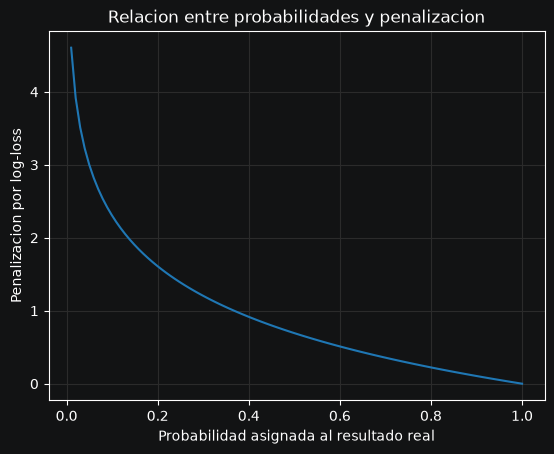

In [133]:
xs = np.linspace(0.01, 1, 101)
ys = -np.log(xs)

plt.plot(xs, ys)
plt.xlabel("Probabilidad asignada al resultado real")
plt.ylabel("Penalizacion por log-loss")
plt.title("Relacion entre probabilidades y penalizacion")
plt.grid()


Como vemos cada penalizacion individual es exponencialmente mas alta por valor mas bajo de probabilidad asignado al resultado real, por lo cual la transformacion de probabilidades a valores de log-loss es no lineal.   

Este se valor se interpreta como la "penalizacion" de las predicciones incorrectas del modelo, si el modelo asigna una probabilidad alta al resultado real este produce una penalizacion pequenia, y si le asigna una probabilidad baja al resultado real produce una penalizacion alta. 

En consecuencia, como el log loss es el promedio de estos, un valor menor de log loss indicara que el modelo le asigna mayor probabilidad a los resultados que realmente ocurrieron. Esto ultimo es lo que nos interesa. 

Cabe destacar que como el log loss es un promedio, y la transformacion de probabilidades a log-loss es no lineal, una probabilidad real asignada baja en el modelo puede mover mucho el promedio del log-loss.

In [134]:
probabilidad_real = predicciones_M5a["p_real"]

log_loss = -np.log(probabilidad_real).mean()
log_loss

np.float64(0.45369024612258607)

Se puede resumir este proceso con la funcion log_loss de sklearn que devuelve el log loss al pasarle una prediccion entre categorias con probabilidades, las categorias con el mismo orden, y el resultado observado:

In [135]:
from sklearn.metrics import log_loss

clases = ["away team win", "draw", "home team win"]

probabilidades = predicciones_M5a[["p_away", "p_draw", "p_home"]].to_numpy()

lg_loss = log_loss(y_real, probabilidades, labels=clases)
lg_loss


0.45369024612258607

Podemos generalizar este proceso para obtener estos valores para cada modelo en un dataframe, luego comparar sus resultados:  

La siguiente funcion generaliza este proceso.  
Utilizamos funciones de sklearn que sirven para conseguir estos valores:

In [136]:
def evaluar_modelo(predicciones):
    clases = ["away team win", "draw", "home team win"]

    y_real = predicciones["result"]
    y_pred = predicciones["prediccion"]

    accuracy = accuracy_score(y_real, y_pred)

    probabilidades = predicciones[
            ["p_away", "p_draw", "p_home"]
        ].to_numpy()

    perdida_log = log_loss(
        y_real,
        probabilidades,
        labels=clases
    )

    return {
        "accuracy": accuracy,
        "log_loss": perdida_log
    }


In [137]:
predicciones_modelos = {
    "M1": predicciones_M1,
    "M2": predicciones_M2,
    "M2a": predicciones_M2a,
    "M3": predicciones_M3,
    "M3a": predicciones_M3a,
    "M4": predicciones_M4,
    "M4a": predicciones_M4a,
    "M5": predicciones_M5,
    "M5a": predicciones_M5a
}


In [138]:
comparacion = pd.DataFrame({
    nombre: evaluar_modelo(predicciones)
    for nombre, predicciones in predicciones_modelos.items()
}).T

display(comparacion)

,accuracy,log_loss
M1,0.80,0.662997
M2,0.80,0.641147
M2a,0.80,0.646467
M3,0.75,0.499377
M3a,0.80,0.503688
M4,0.80,0.634380
M4a,0.80,0.643542
M5,0.80,0.503549
M5a,0.85,0.453690


Como vemos, M5a es el modelo mejor predictivo en la serie de prueba tanto en accuracy como en log_loss, es decir que es la mas consistente dentro de la serie de prueba tanto en los resultados que intenta predecir como en la probabilidad que le asigna a cada resultado real.  
La diferencia de este y modelos como M5 que se ajustaban mucho mejor a los resultados de la serie de entrenamiento pero no pudieron concretar esta mejora de ajuste a la serie de prueba se puede deber a muchas cosas, entre ellas:   
- La cantidad de variables que presentan, que podrian empezar a utilizar para sobreajustarse a la serie de entrenamiento pero asi posiblemente perdiendo generalidad de prediccion. Los modelos mas parsimoniosos probablemente se ven menos afectados por esto.  
- Tambien puede verse simplemente por el tamaño reducido de la muestra, la variabilidad de los partidos o las variables que elegimos.  

Cabe destacar que, como la serie de prueba tiene solamente 20 partidos, cada uno aporta un 5% en el valor de accuracy, lo que hace que este pueda variar. El log loss tambien puede variar mucho por un solo partido al cual el modelo le asigne probabilidades muy altas a resultados no ocurridos.  
Por esto mismo, aun que M5a sea el mejor modelo en esta serie de prueba, no demuestra que sea el mejor modelo fuera de este.  

Veamos como M5a asigna las probabilidades del resultado de la final del mundial que inicialmente habiamos propuesto obtener datos para predecir:   

In [139]:
final = predicciones_M5a.loc[predicciones_M5a["match_id"] == 48065]
final

,match_id,date,home_team,away_team,result,p_away,p_draw,p_home,prediccion,correcta,p_real
103,48065,2026-07-19,Spain,Argentina,home team win,0.096658,0.223856,0.679486,home team win,True,0.679486


Podemos visualizar mejor las probabilidades en un grafico de torta, donde la suma de las probabilidades debe de ser uno:

In [140]:
p_espania = final["p_home"].iloc[0]
p_empate = final["p_draw"].iloc[0]
p_argentina = final["p_away"].iloc[0]
p_empate + p_espania + p_argentina

np.float64(1.0)

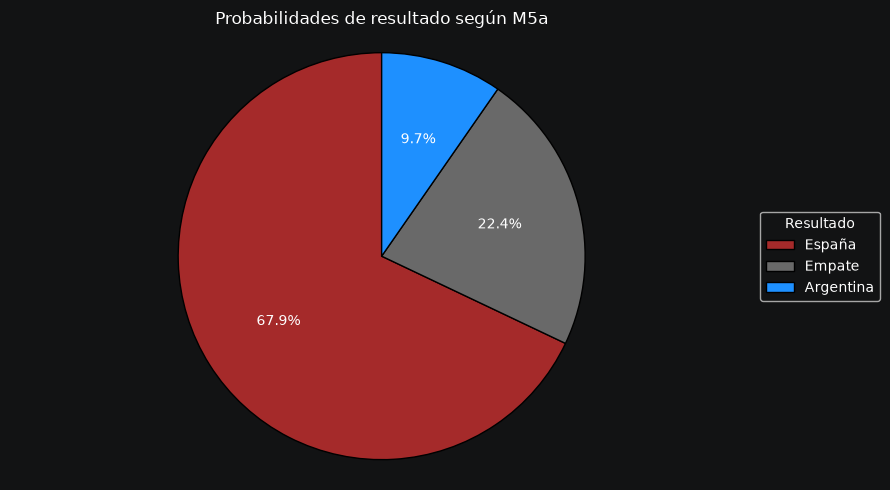

In [141]:
probabilidades = [p_espania, p_empate, p_argentina]
etiquetas = ["España", "Empate", "Argentina"]
colores = ["brown", "dimgray", "dodgerblue"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.pie(
    probabilidades,
    labels=None,
    colors=colores,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "black"}
)

# Tabla de categorías y colores a la derecha
ax.legend(
    etiquetas,
    title="Resultado",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set_title("Probabilidades de resultado según M5a")
ax.axis("equal")

plt.tight_layout()
plt.show()

### DONDE SE PUEDEN ANIADIR PLOTS: POR EL MOMENTO, A TODAS LAS SECCIONES MENOS A CREANDO LOS MODELOS

Podes aniadir Cross Validation para entender la seguridad de los parametros de los modelos, pero antes de poder utilizar cross validation tenes que verificar que tan independientes son las muestras entre si (partidos pasados con partidos futuros para evitar data leakage).

### ¿Mas informacion o mas tamaño de muestra?

En este notebook vimos el procedimiento para crear un modelo con los datos del mundial 2026, que nos permite utilizar varios tipos de datos para predecir un partido: 
- Elo
- Momentum previo al mundial (estadisticas de results_shootouts rs)
- Rendimiento en el mundial (estadisticas de world_cup_matches wcm)
- Datos del desarrollo de los partidos en el mundial (sot, shots, possession y xg)

Pero la poca disponibilidad de estas variables a traves del tiempo limito la cantidad de informacion (partidos) con las que pudimos entrenar nuestros modelos.  
Esto nos lleva a plantear la siguietne pregunta:  
¿Es mejor entrenar el modelo variables mas diversas y una muestra reducida, o utilizar menos variables pero tenes mas informacion de partidos?  

Podemos tomar los modelos que ya hicimos como un ejemplo del modelo con muestra reducida y multiples variables con distintos tipos de informacion.  
Exploraremos en otro notebook modelos con mayor tamanio de muestra.  


In [142]:
predicciones_M5a.to_csv("predicciones_M5a.csv", index=False)